# 01 · BCCD data exploration

Phase 2 of [project.md](../project.md). Questions this notebook answers:

1. How many images and objects per split and class?
2. What do the images and boxes look like?
3. **Typical cell sizes**, which seed the radius `r` used by every parameter.
4. How much do **staining and lighting** vary between images?
5. Which **channel** best separates the purple stain (WBC nuclei, platelets) from RBCs?
6. How many RBCs are **missing a box**?
7. Where are the **hard cases** (crowding, overlap, border cells)?
8. Are there **shifted frames of the same field** across splits (leakage)?

Prerequisites: `scripts/build_index.py` and `scripts/make_splits.py` have been run.

In [ ]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from skimage import color, filters, transform

from bloodcells.config import load_config
from bloodcells.datasets import rbc_radius_from_boxes
from bloodcells.io_utils import load_image

cfg = load_config()
P = cfg["paths"]
FIG = P["results"] / "figures" / "exploration"
TAB = P["results"] / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

images = pd.read_csv(P["index"] / "bccd_images.csv")
all_boxes = pd.read_csv(P["index"] / "bccd_boxes.csv")
boxes = all_boxes[~all_boxes["duplicate"]]  # repeated boxes (IoU >= 0.7) are annotation errors
splits = json.loads(P["splits"].read_text(encoding="utf-8"))
image_path = images.set_index("image_id")["image_path"]
boxes_of = {k: g for k, g in boxes.groupby("image_id")}

CLASSES = ["RBC", "WBC", "Platelet"]
COLORS = {"RBC": "tab:red", "WBC": "tab:blue", "Platelet": "tab:green"}
SPLIT_ORDER = ["train", "val", "test"]
rng = np.random.default_rng(cfg["seed"])
R_REF = rbc_radius_from_boxes(boxes)
pd.set_option("display.precision", 2)
plt.rcParams["figure.dpi"] = 60
%config InlineBackend.figure_formats = ["jpeg"]
print(f"{len(images)} images, {len(boxes)} boxes "
      f"({all_boxes['duplicate'].sum()} duplicate boxes removed), reference RBC radius r = {R_REF:.1f} px")

364 images, 4878 boxes (8 duplicate boxes removed), reference RBC radius r = 52.0 px


## 1. Dataset summary

In [ ]:
summary = boxes.pivot_table(index="split", columns="cls", values="image_id", aggfunc="count", fill_value=0)
summary = summary.reindex(index=SPLIT_ORDER, columns=CLASSES)
summary.insert(0, "images", images["split"].value_counts().reindex(SPLIT_ORDER))
for c in CLASSES:
    summary[f"{c}/image"] = summary[c] / summary["images"]
summary.loc["total"] = summary.loc[SPLIT_ORDER].sum()
summary.loc["total", [f"{c}/image" for c in CLASSES]] = (
    summary.loc["total", CLASSES] / summary.loc["total", "images"]
).to_numpy()
summary

cls,images,RBC,WBC,Platelet,RBC/image,WBC/image,Platelet/image
split,,,,,,,
train,205.0,2376.0,214.0,209.0,11.59,1.04,1.02
val,87.0,965.0,87.0,83.0,11.09,1.00,0.95
test,72.0,804.0,71.0,69.0,11.17,0.99,0.96
total,364.0,4145.0,372.0,361.0,11.39,1.02,0.99


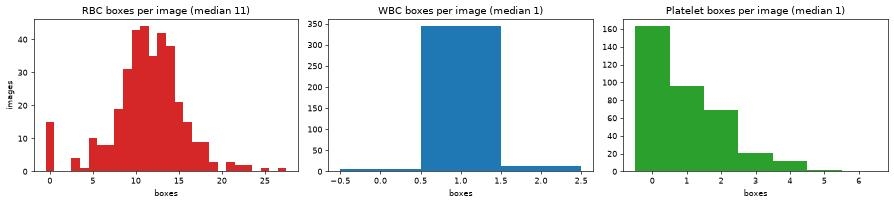

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, CLASSES):
    counts = images[f"n_{c}"]
    ax.hist(counts, bins=np.arange(counts.max() + 2) - 0.5, color=COLORS[c])
    ax.set_title(f"{c} boxes per image (median {counts.median():.0f})")
    ax.set_xlabel("boxes")
axes[0].set_ylabel("images")
fig.tight_layout()
fig.savefig(FIG / "boxes_per_image.png", dpi=120)

## 2. Random samples with their boxes

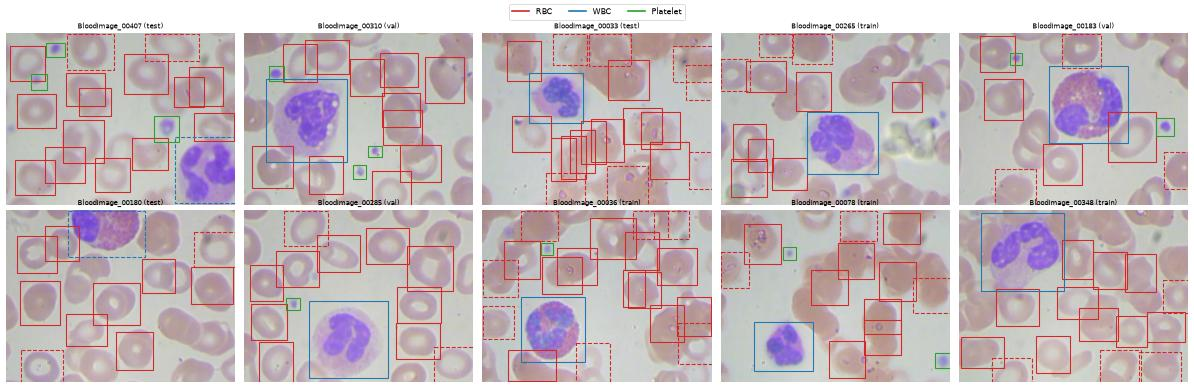

In [ ]:
LEGEND = [Line2D([0], [0], color=COLORS[c], lw=2, label=c) for c in CLASSES]


def show(ax, image_id, title=None, draw_boxes=True):
    ax.imshow(load_image(image_path[image_id]))
    if draw_boxes and image_id in boxes_of:
        for b in boxes_of[image_id].itertuples():
            ls = "--" if b.truncated else "-"
            ax.add_patch(Rectangle((b.xmin, b.ymin), b.width, b.height, fill=False,
                                   ec=COLORS[b.cls], lw=1.3, ls=ls))
    ax.set_title(title or image_id, fontsize=8)
    ax.axis("off")


sample = rng.choice(images["image_id"], 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(20, 6.5))
for ax, image_id in zip(axes.flat, sample):
    split = images.set_index("image_id").loc[image_id, "split"]
    show(ax, image_id, f"{image_id} ({split})")
fig.legend(handles=LEGEND, loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG / "random_samples.png", dpi=120)

## 3. Typical cell sizes

Only complete (non-truncated) boxes. The box diameter is `(width + height) / 2`.
Sizes are also given relative to the RBC radius `r`, the unit used in `config.yaml`.

In [ ]:
complete = boxes[~boxes["truncated"]].copy()
complete["diameter"] = (complete["width"] + complete["height"]) / 2
complete["aspect"] = complete["width"] / complete["height"]

sizes = complete.groupby("cls")["diameter"].describe(percentiles=[0.05, 0.5, 0.95])
sizes = sizes.rename(columns={"5%": "p5", "50%": "median", "95%": "p95"})[["count", "p5", "median", "p95"]]
sizes["radius_in_r"] = sizes["median"] / (2 * R_REF)
sizes["area_in_pi_r2"] = sizes["radius_in_r"] ** 2
sizes["aspect_median"] = complete.groupby("cls")["aspect"].median()
sizes = sizes.reindex(CLASSES)
sizes.to_csv(TAB / "typical_sizes.csv")
sizes

,count,p5,median,p95,radius_in_r,area_in_pi_r2,aspect_median
cls,,,,,,,
RBC,3157.0,87.00,104.00,122.00,1.00,1.00,1.03
WBC,268.0,122.17,194.25,241.32,1.87,3.49,1.06
Platelet,323.0,30.50,39.50,54.00,0.38,0.14,1.05


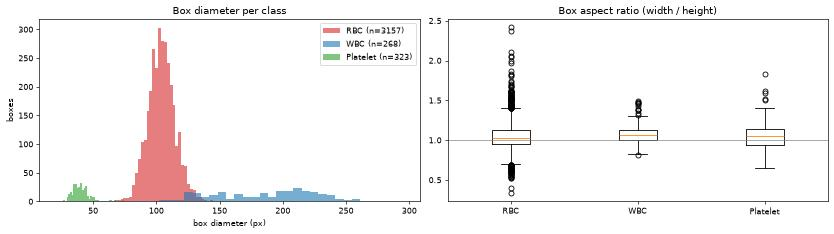

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for c in CLASSES:
    d = complete.loc[complete["cls"] == c, "diameter"]
    axes[0].hist(d, bins=40, alpha=0.6, color=COLORS[c], label=f"{c} (n={len(d)})")
axes[0].set_xlabel("box diameter (px)")
axes[0].set_ylabel("boxes")
axes[0].legend()
axes[0].set_title("Box diameter per class")
axes[1].boxplot([complete.loc[complete["cls"] == c, "aspect"] for c in CLASSES], tick_labels=CLASSES)
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_title("Box aspect ratio (width / height)")
fig.tight_layout()
fig.savefig(FIG / "box_sizes.png", dpi=120)

## 4. Staining and lighting variation

Per-image statistics on a 4x downsampled image: mean Lab color and the
green-channel background level (90th percentile) and contrast (p90 − p10).

In [ ]:
def image_stats(path):
    img = load_image(path)[::4, ::4]
    lab = color.rgb2lab(img)
    g = img[..., 1].astype(float)
    p10, p90 = np.percentile(g, [10, 90])
    return {"L": lab[..., 0].mean(), "a": lab[..., 1].mean(), "b": lab[..., 2].mean(),
            "green_bg": p90, "green_contrast": p90 - p10}


stats = pd.DataFrame([image_stats(p) for p in images["image_path"]], index=images["image_id"])
stats["split"] = images.set_index("image_id")["split"]
stats.describe().loc[["mean", "std", "min", "max"]]

,L,a,b,green_bg,green_contrast
mean,73.43,4.99,-1.16,204.98,59.10
std,1.31,1.15,1.52,2.51,5.08
min,67.39,2.09,-5.34,189.00,32.00
max,78.28,7.95,2.31,210.00,72.00


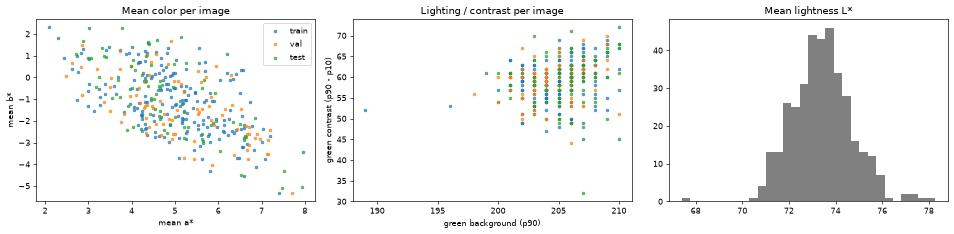

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for s in SPLIT_ORDER:
    sub = stats[stats["split"] == s]
    axes[0].scatter(sub["a"], sub["b"], s=10, label=s, alpha=0.7)
    axes[1].scatter(sub["green_bg"], sub["green_contrast"], s=10, label=s, alpha=0.7)
axes[0].set_xlabel("mean a*")
axes[0].set_ylabel("mean b*")
axes[0].set_title("Mean color per image")
axes[1].set_xlabel("green background (p90)")
axes[1].set_ylabel("green contrast (p90 - p10)")
axes[1].set_title("Lighting / contrast per image")
axes[0].legend()
axes[2].hist(stats["L"], bins=30, color="grey")
axes[2].set_title("Mean lightness L*")
fig.tight_layout()
fig.savefig(FIG / "color_variation.png", dpi=120)

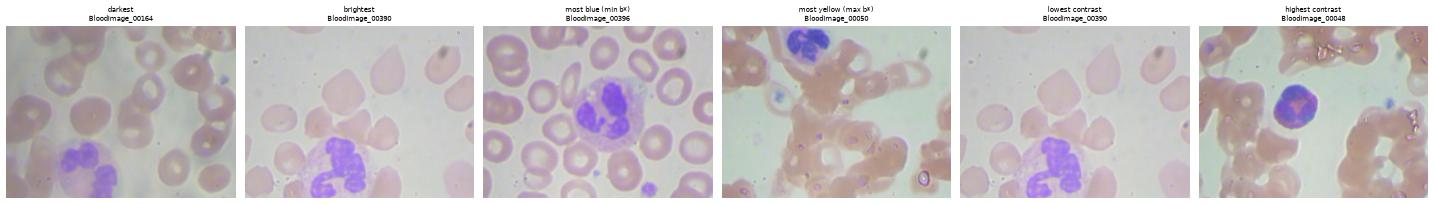

In [ ]:
extremes = {
    "darkest": stats["L"].idxmin(),
    "brightest": stats["L"].idxmax(),
    "most blue (min b*)": stats["b"].idxmin(),
    "most yellow (max b*)": stats["b"].idxmax(),
    "lowest contrast": stats["green_contrast"].idxmin(),
    "highest contrast": stats["green_contrast"].idxmax(),
}
fig, axes = plt.subplots(1, 6, figsize=(24, 3.6))
for ax, (name, image_id) in zip(axes, extremes.items()):
    show(ax, image_id, f"{name}\n{image_id}", draw_boxes=False)
fig.tight_layout()
fig.savefig(FIG / "color_extremes.png", dpi=120)

## 5. Which channel separates the purple stain?

Pixels are sampled from the **center of WBC boxes** (mostly nucleus) and the
**center of RBC boxes**, on train images only. Separability is measured by the
Fisher ratio `(μ1 − μ2)² / (σ1² + σ2²)` (higher = easier to threshold).
This is a proxy: the WBC box center also contains some cytoplasm.

In [ ]:
def channels(img):
    lab = color.rgb2lab(img)
    hsv = color.rgb2hsv(img)
    return {
        "green (inverted)": 255 - img[..., 1].astype(float),
        "-b* (Lab)": -lab[..., 2],
        "a* (Lab)": lab[..., 1],
        "saturation (HSV)": hsv[..., 1],
        "red - green": img[..., 0].astype(float) - img[..., 1],
        "blue - green": img[..., 2].astype(float) - img[..., 1],
    }


def center_crop(b, frac):
    cx, cy = (b.xmin + b.xmax) / 2, (b.ymin + b.ymax) / 2
    hw, hh = b.width * frac / 2, b.height * frac / 2
    return slice(int(cy - hh), int(cy + hh) + 1), slice(int(cx - hw), int(cx + hw) + 1)


train_ids = rng.choice(splits["train"], 60, replace=False)
samples = {"WBC": {}, "RBC": {}}
for image_id in train_ids:
    img = load_image(image_path[image_id])
    ch = channels(img)
    for b in boxes_of.get(image_id, pd.DataFrame()).itertuples():
        if b.cls not in samples or b.truncated:
            continue
        ys, xs = center_crop(b, 0.4 if b.cls == "WBC" else 0.6)
        for name, arr in ch.items():
            vals = arr[ys, xs].ravel()
            vals = rng.choice(vals, min(len(vals), 400), replace=False)
            samples[b.cls].setdefault(name, []).append(vals)
samples = {c: {k: np.concatenate(v) for k, v in d.items()} for c, d in samples.items()}

rows = []
for name in samples["WBC"]:
    w, r = samples["WBC"][name], samples["RBC"][name]
    rows.append({"channel": name, "fisher": (w.mean() - r.mean()) ** 2 / (w.var() + r.var()),
                 "WBC mean": w.mean(), "RBC mean": r.mean()})
separability = pd.DataFrame(rows).sort_values("fisher", ascending=False).set_index("channel")
separability.to_csv(TAB / "channel_separability.csv")
separability

,fisher,WBC mean,RBC mean
channel,,,
-b* (Lab),7.62,42.80,-1.14
blue - green,7.45,90.44,2.95
saturation (HSV),4.83,0.45,0.12
a* (Lab),4.83,31.85,7.78
green (inverted),3.04,143.58,89.50
red - green,0.42,29.80,19.73


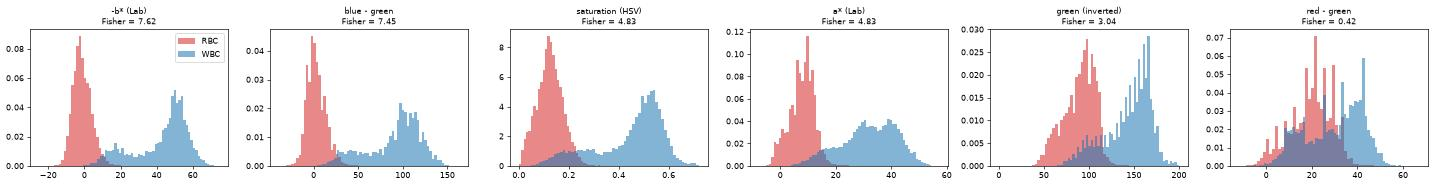

In [ ]:
fig, axes = plt.subplots(1, len(separability), figsize=(4 * len(separability), 3.2))
for ax, name in zip(axes, separability.index):
    for c, col in (("RBC", "tab:red"), ("WBC", "tab:blue")):
        ax.hist(samples[c][name], bins=60, alpha=0.55, density=True, color=col, label=c)
    ax.set_title(f"{name}\nFisher = {separability.loc[name, 'fisher']:.2f}", fontsize=9)
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "channel_separability.png", dpi=120)

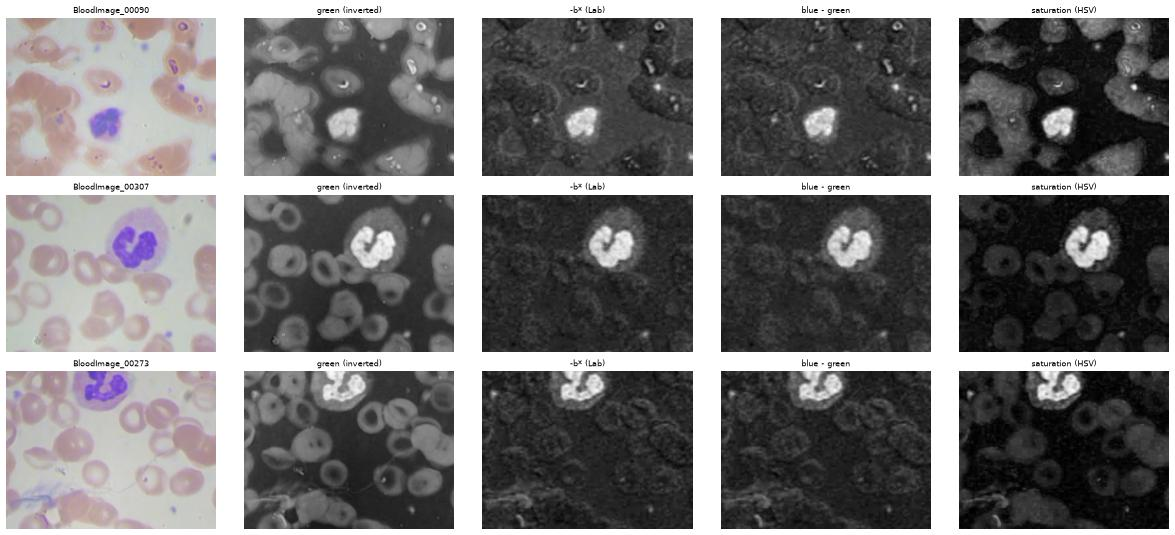

In [ ]:
demo = [i for i in train_ids if images.set_index("image_id").loc[i, "n_Platelet"] > 0][:3]
names = ["green (inverted)"] + list(separability.index[:3])
names = list(dict.fromkeys(names))
fig, axes = plt.subplots(len(demo), len(names) + 1, figsize=(4 * (len(names) + 1), 3 * len(demo)))
for row, image_id in zip(axes, demo):
    img = load_image(image_path[image_id])
    ch = channels(img)
    row[0].imshow(img)
    row[0].set_title(image_id, fontsize=9)
    for ax, name in zip(row[1:], names):
        ax.imshow(ch[name], cmap="gray")
        ax.set_title(name, fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "channels_demo.png", dpi=120)

## 6. How many RBCs have no box?

Crude estimate: Otsu on the green channel + hole filling gives a cell mask; the
cell area **outside every box**, divided by the area of a typical RBC (`π r²`),
estimates the number of unlabelled cells. Small fragments (< 0.3 π r²) are ignored.

In [ ]:
RBC_AREA = np.pi * R_REF**2


def unlabelled_estimate(image_id):
    img = load_image(image_path[image_id])
    g = img[..., 1].astype(float)
    mask = ndi.binary_fill_holes(g < filters.threshold_otsu(g))
    covered = np.zeros_like(mask)
    for b in boxes_of.get(image_id, pd.DataFrame()).itertuples():
        covered[b.ymin:b.ymax, b.xmin:b.xmax] = True
    outside = mask & ~covered
    lab, n = ndi.label(outside)
    areas = ndi.sum(outside, lab, index=np.arange(1, n + 1)) if n else np.array([])
    big = areas[areas >= 0.3 * RBC_AREA]
    return {"cell_fraction_outside_boxes": outside.sum() / max(mask.sum(), 1),
            "est_missing_rbc": big.sum() / RBC_AREA}


unl = pd.DataFrame([unlabelled_estimate(i) for i in images["image_id"]], index=images["image_id"])
unl["n_RBC"] = images.set_index("image_id")["n_RBC"]
unl["est_missing_share"] = unl["est_missing_rbc"] / (unl["est_missing_rbc"] + unl["n_RBC"])
print(f"Labelled RBC boxes: {unl['n_RBC'].sum()}")
print(f"Estimated unlabelled RBCs: {unl['est_missing_rbc'].sum():.0f}")
print(f"Estimated share of RBCs without a box: {unl['est_missing_rbc'].sum() / (unl['est_missing_rbc'].sum() + unl['n_RBC'].sum()):.1%}")
unl.describe().loc[["mean", "50%", "max"]]

Labelled RBC boxes: 4145
Estimated unlabelled RBCs: 1812
Estimated share of RBCs without a box: 30.4%


,cell_fraction_outside_boxes,est_missing_rbc,n_RBC,est_missing_share
mean,0.36,4.98,11.39,0.31
50%,0.34,4.55,11.00,0.28
max,0.99,17.62,27.00,1.00


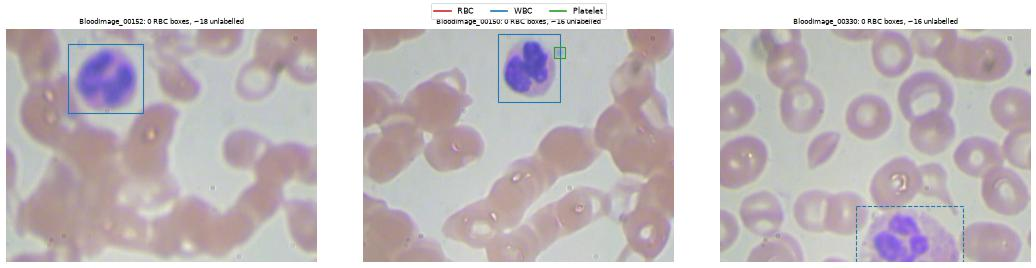

In [ ]:
worst = unl.sort_values("est_missing_rbc", ascending=False).index[:3]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, image_id in zip(axes, worst):
    show(ax, image_id, f"{image_id}: {unl.loc[image_id, 'n_RBC']} RBC boxes, "
                       f"~{unl.loc[image_id, 'est_missing_rbc']:.0f} unlabelled")
fig.legend(handles=LEGEND, loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "unlabelled_rbcs.png", dpi=120)

### Images without any RBC box

Some images contain plenty of RBCs but have **no RBC box at all**
(`no_rbc_labels` in the index). They are kept for WBC/platelet work, but
excluded from RBC counting metrics and from RBC training labels.

15 images without RBC boxes: {'test': 3, 'train': 8, 'val': 4}


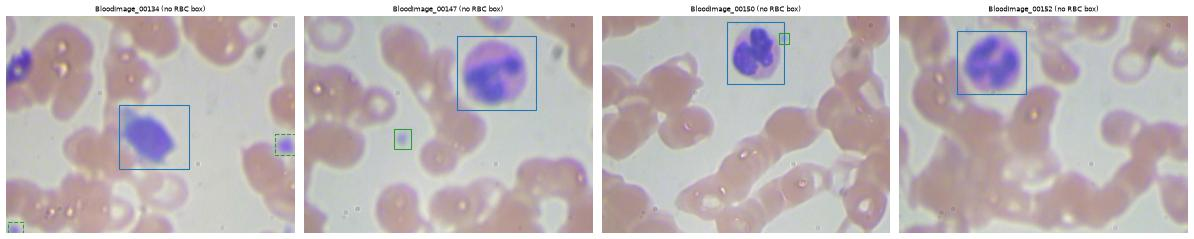

In [ ]:
no_rbc = images[images["no_rbc_labels"]]
print(f"{len(no_rbc)} images without RBC boxes:", no_rbc.groupby("split").size().to_dict())
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, image_id in zip(axes, no_rbc["image_id"][:4]):
    show(ax, image_id, f"{image_id} (no RBC box)")
fig.tight_layout()
fig.savefig(FIG / "no_rbc_labels.png", dpi=120)

## 7. Hard cases: crowding, overlap, border cells

Overlap = pairs of RBC boxes of the same image with IoU > 0.2 (a proxy for
touching or overlapping cells, which the watershed must split).

In [ ]:
def iou_matrix(b):
    x1 = np.maximum(b.xmin.values[:, None], b.xmin.values[None])
    y1 = np.maximum(b.ymin.values[:, None], b.ymin.values[None])
    x2 = np.minimum(b.xmax.values[:, None], b.xmax.values[None])
    y2 = np.minimum(b.ymax.values[:, None], b.ymax.values[None])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = (b.width * b.height).values
    return inter / (area[:, None] + area[None] - inter)


rows = []
for image_id, b in boxes.groupby("image_id"):
    rbc = b[b["cls"] == "RBC"]
    iou = iou_matrix(rbc) if len(rbc) > 1 else np.zeros((1, 1))
    rows.append({"image_id": image_id,
                 "overlap_pairs": int((np.triu(iou, 1) > 0.2).sum()),
                 "truncated_share": b["truncated"].mean()})
hard = pd.DataFrame(rows).set_index("image_id")
print(f"RBC pairs with IoU > 0.2: {hard['overlap_pairs'].sum()} in "
      f"{(hard['overlap_pairs'] > 0).sum()} images")
print(f"Share of all boxes touching the border (truncated): {boxes['truncated'].mean():.1%}")
hard.describe().loc[["mean", "50%", "max"]]

RBC pairs with IoU > 0.2: 253 in 126 images
Share of all boxes touching the border (truncated): 23.2%


,overlap_pairs,truncated_share
mean,0.7,0.23
50%,0.0,0.23
max,9.0,1.00


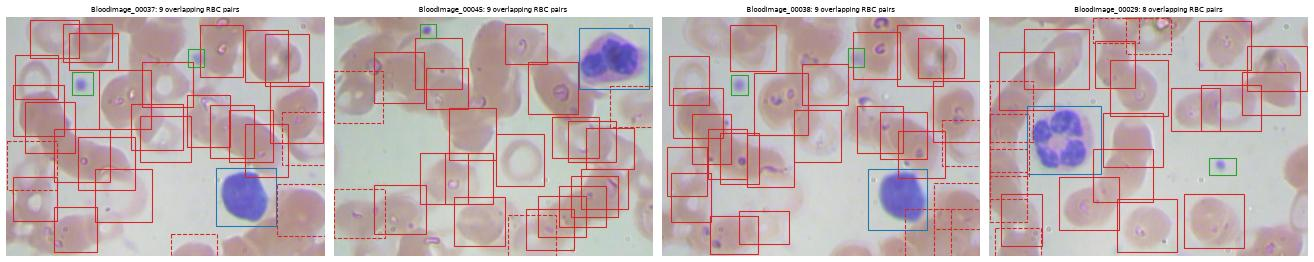

In [ ]:
crowded = hard.sort_values("overlap_pairs", ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, image_id in zip(axes, crowded):
    show(ax, image_id, f"{image_id}: {hard.loc[image_id, 'overlap_pairs']} overlapping RBC pairs")
fig.tight_layout()
fig.savefig(FIG / "crowded_images.png", dpi=120)

## 8. Same field, different frames (leakage check)

BCCD contains **shifted frames of the same microscope field**: the same cells
appear in two images. A perceptual hash misses most of them (it is not
shift-invariant), so `scripts/build_index.py` registers every pair of images by
**phase correlation** and keeps pairs whose overlapping areas correlate strongly
(`bloodcells.datasets.same_field_pairs`). Linked images form a `field_group`.

In [ ]:
pairs = pd.read_csv(P["index"] / "bccd_same_field_pairs.csv")
pairs["cross_split"] = pairs["split_a"] != pairs["split_b"]
print(f"{len(pairs)} same-field pairs, {pairs['cross_split'].sum()} of them across official splits")
print(f"overlap range {pairs['overlap'].min():.2f}-{pairs['overlap'].max():.2f}, "
      f"correlation range {pairs['ncc'].min():.3f}-{pairs['ncc'].max():.3f}")
pairs.sort_values("ncc", ascending=False)

17 same-field pairs, 11 of them across official splits
overlap range 0.35-1.00, correlation range 0.927-0.983


,image_a,image_b,dy,dx,overlap,ncc,split_a,split_b,cross_split
7,BloodImage_00230,BloodImage_00257,-44,28,0.87,0.98,val,train,True
14,BloodImage_00382,BloodImage_00395,-44,44,0.85,0.98,train,train,False
16,BloodImage_00386,BloodImage_00391,-8,-28,0.94,0.98,val,test,True
2,BloodImage_00205,BloodImage_00276,200,-80,0.51,0.98,test,train,True
5,BloodImage_00227,BloodImage_00260,-32,-48,0.86,0.97,test,val,True
1,BloodImage_00204,BloodImage_00277,72,-72,0.75,0.97,train,val,True
3,BloodImage_00206,BloodImage_00278,-44,164,0.68,0.96,train,train,False
8,BloodImage_00231,BloodImage_00256,0,-64,0.90,0.96,train,train,False
4,BloodImage_00223,BloodImage_00263,28,148,0.72,0.96,val,train,True
10,BloodImage_00242,BloodImage_00249,-144,-28,0.67,0.96,train,test,True


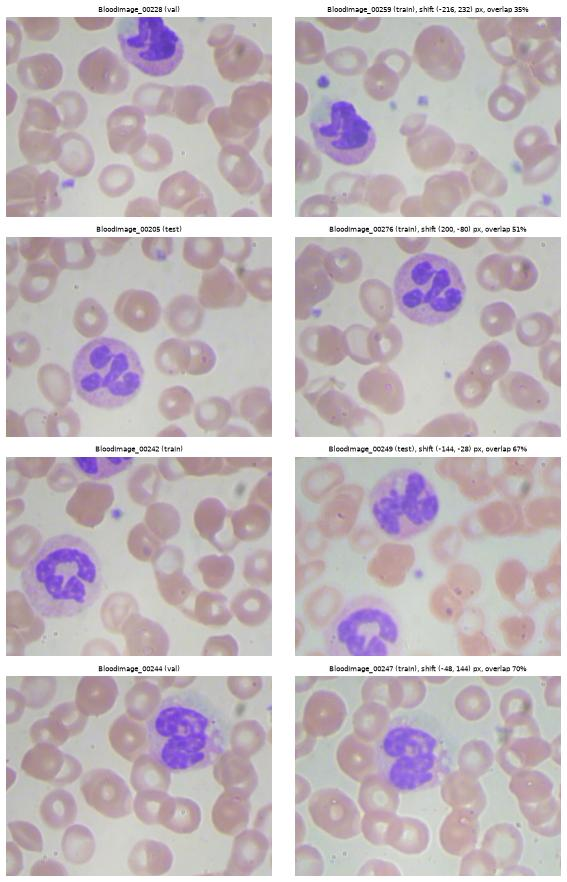

In [ ]:
show_pairs = pairs[pairs["cross_split"]].sort_values("overlap").head(4)
fig, axes = plt.subplots(len(show_pairs), 2, figsize=(10, 3.7 * len(show_pairs)))
for row, p in zip(axes, show_pairs.itertuples()):
    show(row[0], p.image_a, f"{p.image_a} ({p.split_a})", draw_boxes=False)
    show(row[1], p.image_b, f"{p.image_b} ({p.split_b}), shift ({p.dy}, {p.dx}) px, "
                            f"overlap {p.overlap:.0%}", draw_boxes=False)
fig.tight_layout()
fig.savefig(FIG / "same_field_pairs.png", dpi=110)

**Fix applied in `scripts/make_splits.py`:** the official **test set is kept
unchanged** (comparability with other work). Train/val images that share a
field with a test image are excluded; val images that share a field with a
train image move to train. `field_groups` is saved in `splits.json` for
`GroupKFold`.

In [ ]:
print({k: len(splits[k]) for k in ("train", "val", "test", "excluded_leakage", "moved_val_to_train")})
print("excluded for leakage:", splits["excluded_leakage"])

{'train': 209, 'val': 78, 'test': 72, 'excluded_leakage': 5, 'moved_val_to_train': 6}
excluded for leakage: ['BloodImage_00236', 'BloodImage_00242', 'BloodImage_00260', 'BloodImage_00276', 'BloodImage_00386']


## 9. Images proposed for manual pixel annotation

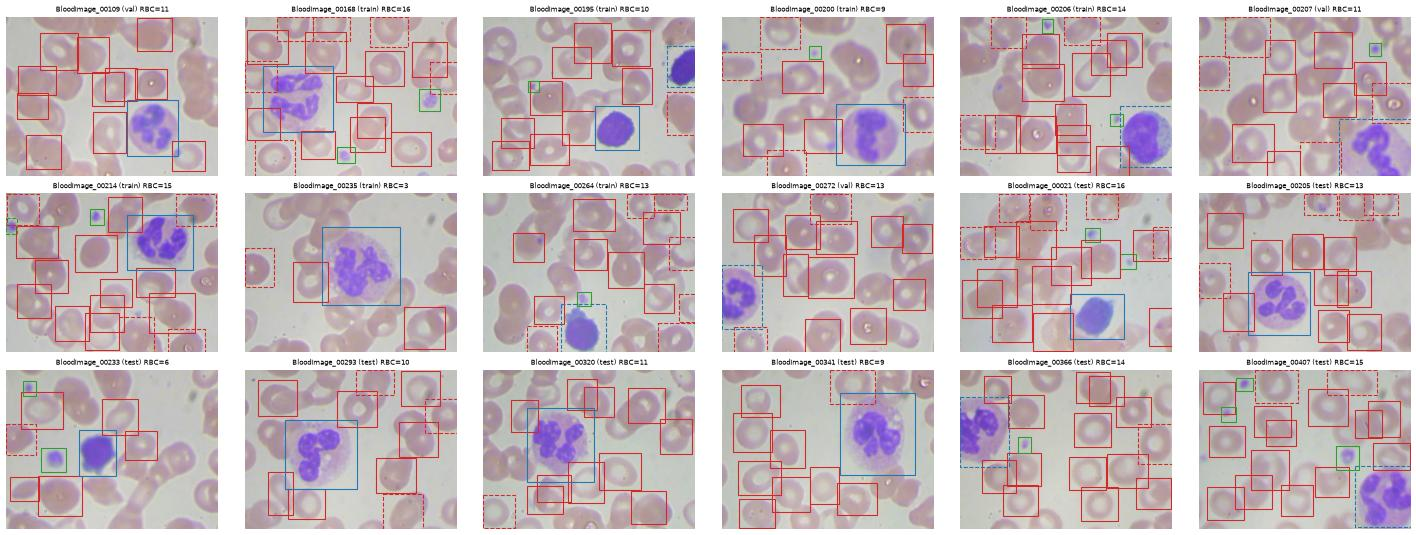

In [ ]:
cands = splits["manual_mask_candidates"]["trainval"] + splits["manual_mask_candidates"]["test"]
fig, axes = plt.subplots(3, 6, figsize=(24, 9))
for ax, image_id in zip(axes.flat, cands):
    row = images.set_index("image_id").loc[image_id]
    show(ax, image_id, f"{image_id} ({row['split']}) RBC={row['n_RBC']}")
fig.tight_layout()
fig.savefig(FIG / "manual_mask_candidates.png", dpi=110)

## 10. Conclusions

| # | Finding | Consequence for the project |
|---|---------|-----------------------------|
| 1 | **364 images**, official split 205 / 87 / 72. Per image: ~11.4 RBC, ~1.0 WBC, ~1.0 platelet boxes; 344 images have exactly one WBC. | WBC detection is mostly "find the single WBC". Labels are imbalanced (RBC : WBC : platelet ≈ 11 : 1 : 1); report per-class metrics. |
| 2 | **Sizes** (median box diameter): RBC 104 px → **r = 52 px**; WBC 194 px (1.87 r, ≈ 3.5 π r²); platelet 39.5 px (0.38 r, ≈ 0.14 π r²). Boxes are nearly square (aspect ≈ 1.03–1.06). | Confirms the `config.yaml` defaults: `r_default: 50`; platelet range [0.02, 0.3] π r² contains 0.14; top-hat SE 2.5 r ≈ 130 px exceeds the WBC radius (≈ 97 px). Granulometry (Phase 3) should find r ≈ 52 px. |
| 3 | **Staining/lighting is consistent**: mean L* 73.4 ± 1.3, b* from −5.3 to 2.3, green background (p90) 189–210. | One microscope and stain protocol. A global Otsu threshold is a reasonable start; illumination correction is kept but its effect will be small (to be measured in the ablation). |
| 4 | **Purple-stain channel**: Fisher ratio WBC vs RBC: −b* **7.62**, blue−green 7.45, saturation 4.83, a* 4.83, inverted green only 3.04. | `purple_channel: lab_b` confirmed. The green channel stays the channel for the cell mask (cells vs background) but is poor at separating nuclei from RBCs. |
| 5 | **≈ 30 % of RBCs have no box** (crude estimate: ~1,800 unlabelled vs 4,145 labelled), and **15 images have no RBC box at all** (8 train, 4 val, 3 test). | RBC precision on BCCD is only a lower bound; exact RBC counts come from the manual masks. `no_rbc_labels` images are excluded from RBC metrics and RBC training labels. |
| 6 | **Crowding**: 253 RBC box pairs with IoU > 0.2 in 126 images (35 %); **23 % of boxes are cut by the image border**. | Splitting touching cells (watershed) matters in a third of the images; border cells need explicit handling (kept for display, excluded from size statistics). |
| 7 | **Leakage**: 17 pairs of images are shifted frames of the same field, **11 across official splits** (a perceptual hash found only 1). | Fixed in `make_splits.py`: test unchanged, 5 train/val images excluded, 6 val images moved to train → **209 / 78 / 72**. Use `field_groups` with `GroupKFold`. |
| 8 | **Annotation errors**: 8 repeated boxes (IoU ≥ 0.7, same class) and 2 empty boxes. | Removed by the index (`duplicate` flag, parser checks). Dense columns of shifted boxes (e.g. 00033) are kept: they look like real overlapping cells. |

**Next:** annotate the 18 manual-mask candidates (section 9), Phase 3 is in notebook 02 (preprocessing and granulometry; the estimated `r` matches the 52 px box radius on 90 % of val images and follows the zoom).